# 01 · Exploración: ¿cuál es la demanda real de Kaido?

**Pregunta 1 del caso:** *"Separe lo que compraron los clientes de las automatriculaciones, las compras adelantadas y los meses en que faltaron coches. ¿Cuánto creció de verdad la demanda en A012?"*

### ¿Por qué explorar antes de modelizar?
Un modelo de series temporales **aprende lo que le das**. Si le das las ventas tal cual:
- aprende las **automatriculaciones** como si fueran clientes → prevé demanda que no existe;
- aprende el **adelanto** de nov–dic A012 como si fuera crecimiento → sobreestima A013;
- aprende los **meses sin coches** como si nadie quisiera comprar → infraestima.

Por eso primero hay que entender qué hay dentro de los datos y limpiarlos.

### Índice
0. Preparación de los datos
1. Visión general: mercado y Kaido
2. ¿Creció de verdad la demanda en A012?
3. Automatriculaciones
4. Sucesos: planes de ayuda, IVA y adelantos
5. ¿Faltaron coches?
6. Conclusiones: qué nos llevamos al modelo

## 0. Preparación de los datos

La carga y limpieza está en `src/datos.py` para reutilizarla en todo el proyecto (notebooks, modelo, simulación). Aquí solo la llamamos.

`panel_segmento()` junta cuatro ficheros en **una tabla con una fila por mes y segmento**:

| Columna | De dónde sale | Qué es |
|---|---|---|
| `mercado` | `mercado_mensual.csv` (suma de canales) | Matriculaciones del segmento: Kaido + rivales |
| `ventas` | `ventas_mensual.csv` (suma de canales) | Ventas retail de Kaido |
| `automat` | `ventas_mensual.csv` | De ellas, automatriculaciones |
| `stock_total`, `s_0_90`... | `stock_mensual.csv` | Stock en la red a fin de mes |
| **`demanda`** | calculada | **`ventas − automat`**: lo que de verdad compraron clientes |
| `cuota` | calculada | `ventas / mercado` |

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datos import cargar, panel_segmento, macro, SEGMENTOS
from graficos import (estilo, es, eje_miles, eje_fechas, anio_caso, sombrear, guardar,
                      COLORES, NOMBRES, AZUL, ROJO, TINTA, TINTA_2, APAGADO, SUCESO, BANDA, ALERTA)

estilo()
d = cargar()
p = panel_segmento(d)           # índice: (fecha, segmento)

# versión "plana" con columnas de año y mes, más cómoda para agrupar
pl = p.reset_index()
pl["anio"] = pl["fecha"].dt.year
pl["mes"] = pl["fecha"].dt.month

# Ejemplo: diciembre de A012 (año ficticio 2012), todos los segmentos
(p.xs("2012-12-01", level="fecha")[["mercado", "ventas", "automat", "demanda", "stock_total", "cuota"]]
 .style.format(es).format({"cuota": lambda x: es(100 * x, 1) + " %"}))

,mercado,ventas,automat,demanda,stock_total,cuota
segmento,,,,,,
B,17227,112.000000,18.000000,94.000000,97.000000,"0,7 %"
C,13696,510.000000,16.000000,494.000000,1107.000000,"3,7 %"
CSUV,13419,409.000000,41.000000,368.000000,1011.000000,"3,0 %"
MD,1657,50.000000,16.000000,34.000000,125.000000,"3,0 %"
MSUV,15830,1023.000000,166.000000,857.000000,536.000000,"6,5 %"
S,86,74.000000,29.000000,45.000000,1.000000,"86,0 %"
SSUV,12663,540.000000,152.000000,388.000000,0.000000,"4,3 %"


Nota: los años del caso se tratan como años ficticios (**A012 → 2012**). En el código verás `2012`; en los gráficos, `A012`.

## 1. Visión general: mercado y Kaido

**Objetivo.** el contexto de largo plazo. ¿Cómo se ha movido el mercado y qué peso tiene Kaido en él?

**Método.** sumamos por año el mercado de los 7 segmentos y las ventas de Kaido, y calculamos la **cuota** = ventas Kaido / mercado.

In [2]:
anual = pl.groupby("anio")[["mercado", "ventas", "demanda"]].sum()
anual["cuota_%"] = 100 * anual["ventas"] / anual["mercado"]
anual.index = [anio_caso(a) for a in anual.index]
anual.style.format({"mercado": es, "ventas": es, "demanda": es, "cuota_%": lambda x: es(x, 2)})

,mercado,ventas,demanda,cuota_%
A001,704.150,0,0,"0,00"
A002,616.087,0,0,"0,00"
A003,637.977,6.371,5.339,"1,00"
A004,518.854,3.635,2.882,"0,70"
A005,449.578,3.611,2.907,"0,80"
A006,474.281,5.472,4.604,"1,15"
A007,554.861,9.561,8.855,"1,72"
A008,677.441,15.007,13.467,"2,22"
A009,757.935,18.266,16.413,"2,41"
A010,837.217,18.570,16.925,"2,22"


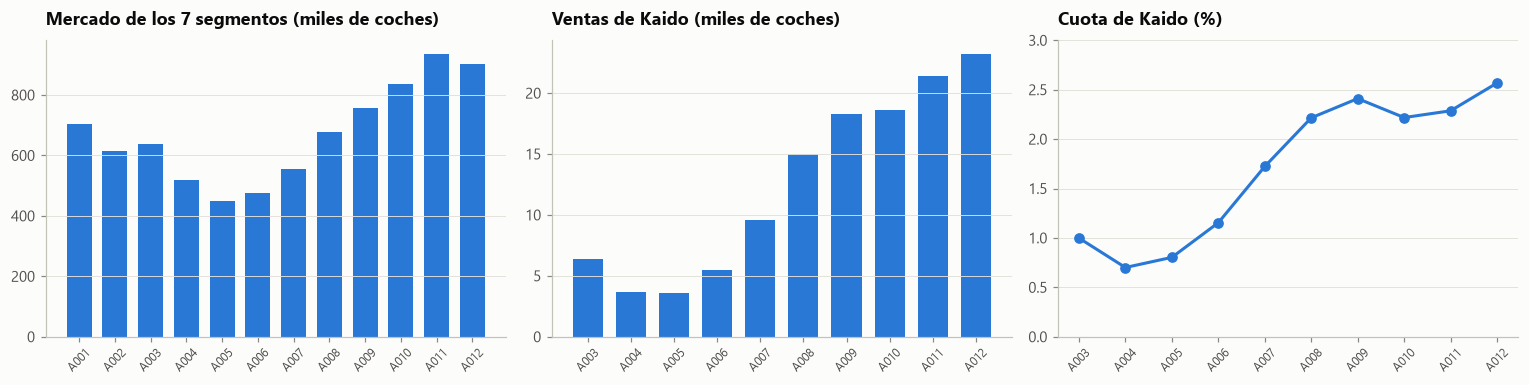

In [3]:
k = anual.loc["A003":]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))

ax[0].bar(anual.index, anual["mercado"] / 1000, color=AZUL, width=0.7)
ax[0].set_title("Mercado de los 7 segmentos (miles de coches)")

ax[1].bar(k.index, k["ventas"] / 1000, color=AZUL, width=0.7)
ax[1].set_title("Ventas de Kaido (miles de coches)")

ax[2].plot(k.index, k["cuota_%"], color=AZUL, marker="o", ms=6)
ax[2].set_title("Cuota de Kaido (%)")
ax[2].set_ylim(0, 3)

for a in ax:
    a.tick_params(axis="x", labelrotation=45, labelsize=8)
fig.tight_layout()
guardar(fig, "01_vision_general")

**Resultados.**
- El **mercado** cae un 36 % de A001 a A005 (crisis), se recupera hasta A011 (934.000) y **en A012 vuelve a caer** (−3,4 %).
- **Kaido** crece mucho más que el mercado: de 3.600 coches en A005 a 23.000 en A012. Su cuota pasa del 0,7 % al **2,6 %**.
- Kaido es pequeño (2,6 % del mercado): **puede crecer aunque el mercado caiga**, quitando clientes a rivales. Por eso el caso separa *mercado × cuota*.

## 2. ¿Creció de verdad la demanda en A012?

**Objetivo.** ver si el +8,5 % de A012 son clientes nuevos o algo más.

**Método.** quitamos capas una a una:
1. **Ventas** → lo que reporta Kaido.
2. **− automatriculaciones** → *demanda limpia* (solo clientes).
3. **− SUV compacto** → *gama de siempre*. El CSUV se lanzó en agosto de A012: no existía en A011, así que para comparar "manzanas con manzanas" lo separamos.

In [4]:
def capas(anio):
    t = pl[pl.anio == anio]
    return pd.Series({
        "Ventas (lo que reporta Kaido)": t.ventas.sum(),
        "− Automatriculaciones": -t.automat.sum(),
        "= Demanda limpia": t.demanda.sum(),
        "− SUV compacto (nuevo)": -t.loc[t.segmento == "CSUV", "demanda"].sum(),
        "= Demanda gama de siempre": t.loc[t.segmento != "CSUV", "demanda"].sum(),
    })

tabla = pd.DataFrame({"A011": capas(2011), "A012": capas(2012)})
tabla["Variación %"] = (100 * (tabla["A012"] / tabla["A011"] - 1)).replace([np.inf, -np.inf], np.nan)
tabla.style.format({"A011": es, "A012": es, "Variación %": lambda x: es(x, 1)})

,A011,A012,Variación %
Ventas (lo que reporta Kaido),21.362,23.175,"8,5"
− Automatriculaciones,-1.819,-2.469,"35,7"
= Demanda limpia,19.543,20.706,"6,0"
− SUV compacto (nuevo),0,-1.192,—
= Demanda gama de siempre,19.543,19.514,"-0,1"


Ahora descomponemos los **+1.813 coches** que Kaido vendió de más en A012: ¿de dónde sale cada uno?

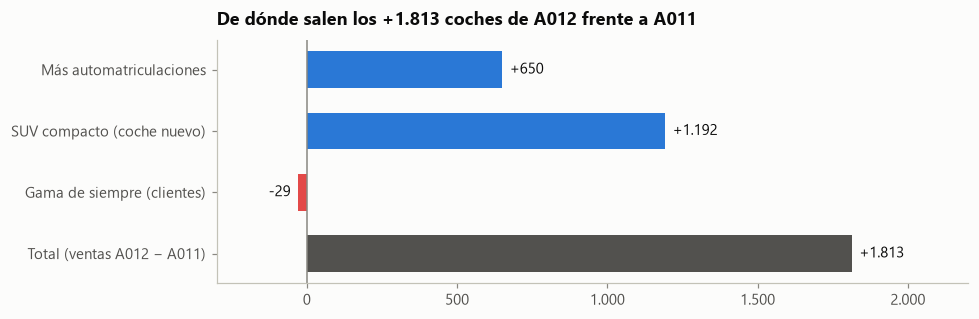

In [5]:
a11, a12 = pl[pl.anio == 2011], pl[pl.anio == 2012]
descomp = pd.Series({
    "Más automatriculaciones": a12.automat.sum() - a11.automat.sum(),
    "SUV compacto (coche nuevo)": a12.loc[a12.segmento == "CSUV", "demanda"].sum(),
    "Gama de siempre (clientes)": (a12.loc[a12.segmento != "CSUV", "demanda"].sum()
                                   - a11.loc[a11.segmento != "CSUV", "demanda"].sum()),
})
descomp["Total (ventas A012 − A011)"] = descomp.sum()

fig, ax = plt.subplots(figsize=(9, 3))
colores = [AZUL if v >= 0 else ROJO for v in descomp.values[:-1]] + [TINTA_2]
y = range(len(descomp))[::-1]
ax.barh(list(y), descomp.values, color=colores, height=0.6)
ax.set_yticks(list(y), descomp.index)
ax.axvline(0, color=APAGADO, lw=1)
for yi, v in zip(y, descomp.values):
    ax.text(v + (25 if v >= 0 else -25), yi, f"{'+' if v > 0 else ''}{es(v)}",
            va="center", ha="left" if v >= 0 else "right", color=TINTA, fontsize=10)
ax.set_xlim(-300, 2200)
ax.grid(False)
ax.set_title("De dónde salen los +1.813 coches de A012 frente a A011")
eje_miles(ax, "x")
fig.tight_layout()
guardar(fig, "02_descomposicion_crecimiento")

**Resultados.**
- La **gama de siempre** (los coches que ya vendía Kaido) se queda **plana**: −29 coches, un −0,1 %.
- El crecimiento viene de un **coche nuevo** (+1.192) y de **más automatriculaciones** (+650).

### Pero cuidado: ¿y el adelanto?
El −0,1 % compara dos años completos, pero **los dos años tienen sucesos dentro**:
- **A011:** adelanto de compras en **agosto** y caída de **septiembre a diciembre**.
- **A012:** adelanto en **noviembre y diciembre** (por la normativa de A013).

Veámoslo mes a mes.

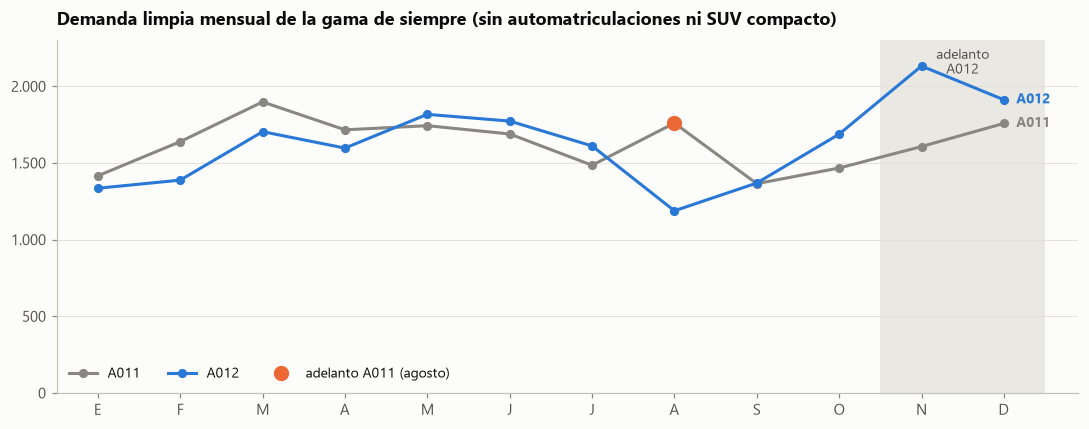

In [6]:
gama = (pl[pl.segmento != "CSUV"]
        .pivot_table(index="mes", columns="anio", values="demanda", aggfunc="sum")[[2011, 2012]])

meses = ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(10.5, 12.5, color=BANDA, lw=0, zorder=0)
ax.text(11.5, 2250, "adelanto\nA012", ha="center", va="top", color=TINTA_2, fontsize=9)
ax.plot(gama.index, gama[2011], color=APAGADO, marker="o", ms=5, label="A011")
ax.plot(gama.index, gama[2012], color=AZUL, marker="o", ms=5, label="A012")
ax.plot([8], [gama.loc[8, 2011]], "o", ms=9, color=SUCESO, zorder=5, label="adelanto A011 (agosto)")
ax.text(12.15, gama.loc[12, 2012], "A012", color=AZUL, va="center", fontsize=9, fontweight="bold")
ax.text(12.15, gama.loc[12, 2011], "A011", color=APAGADO, va="center", fontsize=9, fontweight="bold")
ax.set_xticks(range(1, 13), meses)
ax.set_xlim(0.5, 12.9)
ax.set_ylim(0, 2300)
eje_miles(ax)
ax.set_title("Demanda limpia mensual de la gama de siempre (sin automatriculaciones ni SUV compacto)")
ax.legend(loc="lower left", ncols=3)
fig.tight_layout()
guardar(fig, "03_gama_mensual_A011_A012")

**Resultados.**
- De enero a octubre, A012 va casi siempre **por debajo** de A011.
- En **noviembre y diciembre** A012 se dispara por encima: es el adelanto.
- Agosto A011 está inflado (adelanto) y septiembre–octubre A011 hundidos (caída): **dentro de enero–octubre ambos efectos se compensan** aproximadamente.

### Estimación del adelanto de A012
**Idea:** si la gama de siempre cayó un X % de enero a octubre (sin adelanto), lo normal es que noviembre–diciembre también cayeran ese X %. Lo que se vendió **por encima** de eso es el adelanto.

$$\text{esperado}_{\text{nov–dic A012}} = \text{nov–dic A011} \times (1 + \text{crecimiento ene–oct})$$

In [7]:
eo = gama.loc[1:10].sum()          # enero-octubre
nd = gama.loc[11:12].sum()         # noviembre-diciembre
crec_eo = eo[2012] / eo[2011] - 1
esperado_nd = nd[2011] * (1 + crec_eo)
adelanto = nd[2012] - esperado_nd

total_12 = gama[2012].sum()
subyacente_12 = total_12 - adelanto
crec_sub = subyacente_12 / gama[2011].sum() - 1

pd.Series({
    "Crecimiento ene–oct A012 vs A011 (%)": 100 * crec_eo,
    "Nov–dic A012 esperado sin adelanto": esperado_nd,
    "Nov–dic A012 real": nd[2012],
    "→ Coches adelantados (robados a A013)": adelanto,
    "Demanda gama de siempre A012 sin adelanto": subyacente_12,
    "→ Crecimiento subyacente A012 (%)": 100 * crec_sub,
}).map(lambda x: es(x, 1)).to_frame("valor")

,valor
Crecimiento ene–oct A012 vs A011 (%),"-4,4"
Nov–dic A012 esperado sin adelanto,"3.217,7"
Nov–dic A012 real,"4.044,0"
→ Coches adelantados (robados a A013),"826,3"
Demanda gama de siempre A012 sin adelanto,"18.687,7"
→ Crecimiento subyacente A012 (%),"-4,4"


**Resultados.**
- Sin el adelanto, la gama de siempre **habría caído alrededor de un 4 %** en A012.
- Unos **800 coches** de A012 son en realidad demanda de A013 que se adelantó → **A013 empieza con un "agujero"** (la *caída tras el adelanto*).

**Limitaciones:**
- Es una estimación sencilla: supone que nov–dic se habrían comportado como ene–oct.
- En diciembre de A012 **faltaron coches** (sección 5) → las ventas de nov–dic están recortadas, así que el adelanto real **podría ser algo mayor**.
- El modelo del paso ② lo estimará mejor con una variable `adelanto_compras`.

> **Respuesta a la pregunta 1:** *A012 no fue un buen año. La gama de siempre está plana en el total y, quitando el adelanto, cae ≈4 %. El crecimiento de las ventas viene de un coche nuevo y de automatriculaciones.*

## 3. Automatriculaciones

**Qué son:** coches que el concesionario o la marca matriculan a su nombre para **cumplir objetivos** (y cobrar el margen variable). Cuentan como venta, pero **no son demanda**: ningún cliente los pidió. Luego se venden como "km 0", normalmente con descuento.

**Objetivo.** cuánto pesan, si varían por segmento y si tienen patrón en el calendario.

In [8]:
au = pl[pl.anio >= 2009].groupby(["segmento", "anio"])[["automat", "ventas"]].sum()
pct = (100 * au["automat"] / au["ventas"]).unstack().loc[SEGMENTOS]
pct.columns = [anio_caso(c) for c in pct.columns]
pct.index = [f"{s} · {NOMBRES[s]}" for s in pct.index]
pct.style.format(lambda x: es(x, 1)).set_caption("% de las ventas que son automatriculaciones")

,A009,A010,A011,A012
MSUV · SUV medio,"5,9","5,4","5,9","8,9"
SSUV · SUV pequeño,"8,9","8,6","9,2","9,6"
C · Compacto,"16,1","11,7","7,0","11,8"
B · Pequeño,"14,5","14,2","15,4","8,0"
CSUV · SUV compacto,—,—,—,"16,9"
MD · Berlina media,"11,2","11,8","12,9","21,7"
S · Descapotable,"23,4","13,7","21,7","17,1"


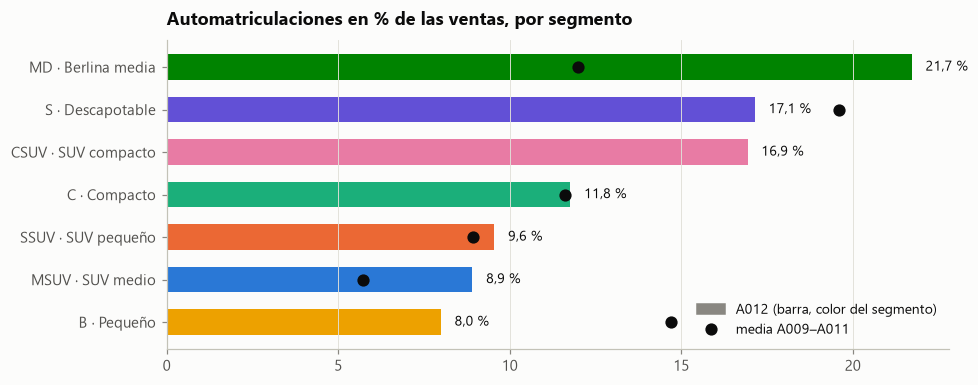

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.6))
orden = pct["A012"].sort_values().index
seg = [i.split(" · ")[0] for i in orden]
ax.barh(orden, pct.loc[orden, "A012"], color=[COLORES[s] for s in seg], height=0.6, label="A012")
media = pct.loc[orden, ["A009", "A010", "A011"]].mean(axis=1)
ax.plot(media, orden, "o", color=TINTA, ms=7, label="media A009–A011")
for i, v in enumerate(pct.loc[orden, "A012"]):
    if v == v:
        ax.text(v + 0.4, i, f"{es(v, 1)} %", va="center", fontsize=9, color=TINTA)
ax.set_title("Automatriculaciones en % de las ventas, por segmento")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ax.legend(handles=[Patch(color=APAGADO, label="A012 (barra, color del segmento)"),
                   Line2D([], [], marker="o", ls="", color=TINTA, ms=7, label="media A009–A011")],
          loc="lower right")
fig.tight_layout()
guardar(fig, "04_automatriculaciones_segmento")

**Resultados.**
- En total son ≈11 % de las ventas, pero **varían mucho por segmento**.
- La **berlina media (MD)** sube al **21,7 %** en A012 (casi el doble que su media): 1 de cada 5 "ventas" no era un cliente.
- El SUV medio, el más vendido, es el más "limpio" (≈9 %).

Ahora, ¿se concentran en algunos meses?

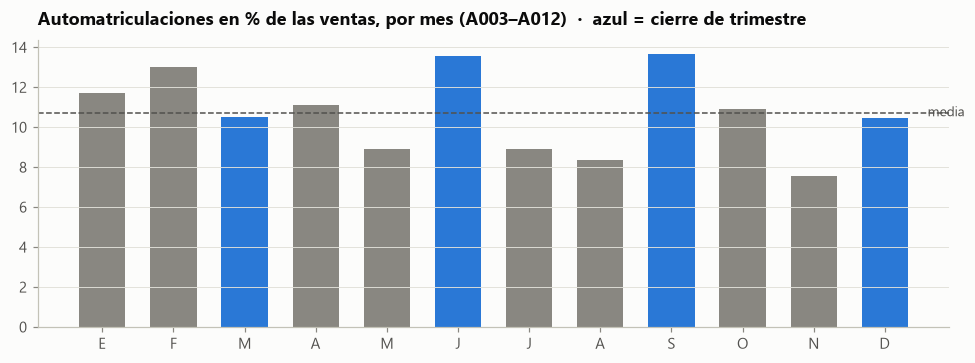

In [10]:
pm = pl[pl.anio >= 2003].groupby("mes")[["automat", "ventas"]].sum()
pm = 100 * pm["automat"] / pm["ventas"]

fig, ax = plt.subplots(figsize=(9, 3.4))
colores = [AZUL if m in (3, 6, 9, 12) else APAGADO for m in pm.index]
ax.bar(pm.index, pm.values, color=colores, width=0.65)
ax.axhline(pm.mean(), color=TINTA_2, lw=1, ls="--")
ax.text(12.6, pm.mean(), "media", va="center", fontsize=9, color=TINTA_2)
ax.set_xticks(range(1, 13), meses)
ax.set_title("Automatriculaciones en % de las ventas, por mes (A003–A012)  ·  azul = cierre de trimestre")
fig.tight_layout()
guardar(fig, "05_automatriculaciones_mes")

**Resultados.** **junio y septiembre** (cierres de semestre y trimestre) están por encima de la media, pero marzo y diciembre no. El patrón existe pero **no es limpio**: hay que tratarlas mes a mes, no con una regla fija.

**Decisión para el modelo:** prevemos la **demanda limpia** (`ventas − automat`).

**Pero ojo para la simulación:** un coche automatriculado **sale del stock igual que uno vendido**. Si Kaido sigue automatriculando un ≈11 %, la producción tiene que cubrirlo. Es una **palanca de decisión** para la recomendación final: automatricular menos = menos coches que fabricar y menos descuentos.

## 4. Sucesos: planes de ayuda, IVA y adelantos

**Qué son:** acontecimientos conocidos que mueven las ventas sin que cambie la demanda de fondo. El fichero `macro_mensual.csv` los marca con 0/1:

| Variable | Qué marca |
|---|---|
| `incentivo_publico` | Meses con plan público de ayuda a la compra |
| `subida_iva` | Mes anterior a una subida del IVA |
| `adelanto_compras` | Meses con compras adelantadas por un cambio de normativa |
| `caida_tras_adelanto` | Meses de caída que siguen a un adelanto |

**Método.** dibujamos el mercado mensual completo con su tendencia (media móvil de 12 meses) y marcamos los sucesos encima.

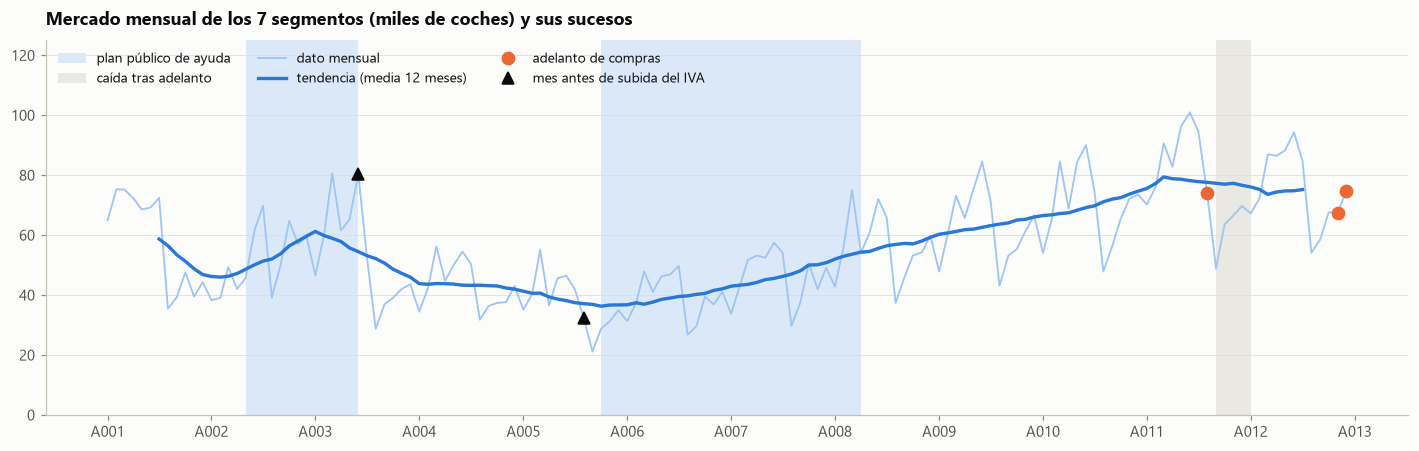

In [11]:
m = pl.groupby("fecha")["mercado"].sum().asfreq("MS")
tendencia = m.rolling(12, center=True).mean()
mac = macro(d).loc[:"2012-12-01"]

fig, ax = plt.subplots(figsize=(13, 4.2))
sombrear(ax, mac["incentivo_publico"], color="#dbe8f8", label="plan público de ayuda")
sombrear(ax, mac["caida_tras_adelanto"], color=BANDA, label="caída tras adelanto")
ax.plot(m.index, m / 1000, color="#9ec5f4", lw=1.2, label="dato mensual")
ax.plot(tendencia.index, tendencia / 1000, color=AZUL, lw=2.2, label="tendencia (media 12 meses)")
ad = mac.index[mac["adelanto_compras"] == 1]
iva = mac.index[mac["subida_iva"] == 1]
ax.plot(ad, m[ad] / 1000, "o", color=SUCESO, ms=8, label="adelanto de compras")
ax.plot(iva, m[iva] / 1000, "^", color=TINTA, ms=8, label="mes antes de subida del IVA")
eje_fechas(ax)
ax.set_ylim(0, 125)
ax.set_title("Mercado mensual de los 7 segmentos (miles de coches) y sus sucesos")
ax.legend(loc="upper left", ncols=3)
fig.tight_layout()
guardar(fig, "06_mercado_sucesos")

**Resultados.**
- Los **planes de ayuda** (A002–A003 y A005–A008) coinciden con tramos en que el mercado sube o deja de caer: **inflan la demanda** mientras duran.
- Antes de cada **subida del IVA** y en cada **adelanto** hay un pico, y después un bache.
- En **agosto de A011** se venden ≈74.000 coches. Parece un mes normal… pero agosto suele ser **el peor mes del año** (−29 % frente a un mes medio). Con la estacionalidad delante, los sucesos se esconden.

Para verlo mejor usamos el consejo del enunciado: **comparar crecimientos con crecimientos**.

### Variación interanual (YoY)
$$\text{YoY}_t = \frac{\text{ventas}_t}{\text{ventas}_{t-12}} - 1$$

Comparar cada mes con **el mismo mes del año anterior** elimina la estacionalidad (agosto siempre es malo, marzo siempre es bueno), y deja ver lo que ha cambiado de verdad.

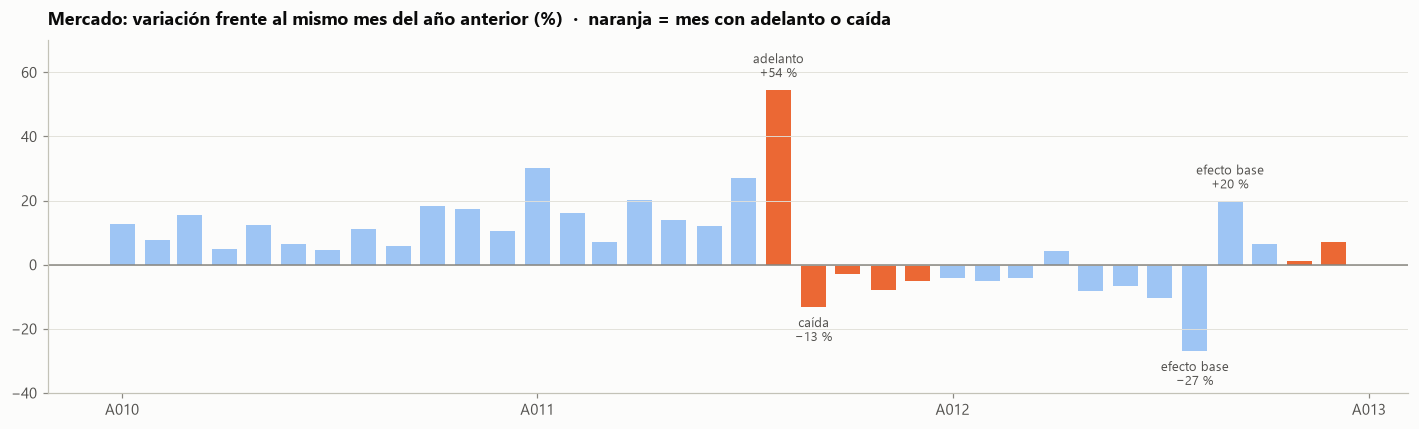

In [12]:
yoy = 100 * (m / m.shift(12) - 1)
y = yoy["2010-01":"2012-12"]
evento = (mac["adelanto_compras"] + mac["caida_tras_adelanto"]).loc[y.index] > 0

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(y.index, y.values, width=22, color=[SUCESO if e else "#9ec5f4" for e in evento])
ax.axhline(0, color=APAGADO, lw=1)
notas = {"2011-08-01": "adelanto\n+54 %", "2011-09-01": "caída\n−13 %",
         "2012-08-01": "efecto base\n−27 %", "2012-09-01": "efecto base\n+20 %"}
for f, txt in notas.items():
    v = y[f]
    ax.text(pd.Timestamp(f), v + (3 if v > 0 else -3), txt, ha="center",
            va="bottom" if v > 0 else "top", fontsize=8.5, color=TINTA_2)
eje_fechas(ax)
ax.set_ylim(-40, 70)
ax.set_title("Mercado: variación frente al mismo mes del año anterior (%)  ·  naranja = mes con adelanto o caída")
fig.tight_layout()
guardar(fig, "07_mercado_yoy")

**Resultados.**
- **Agosto A011: +54 %** (adelanto) y **septiembre A011: −13 %** (caída). El adelanto *roba* ventas a los meses siguientes.
- **Efecto base:** agosto A012 sale −27 % y septiembre A012 +20 %, pero **no pasó nada en A012**: es el espejo de A011. Se compara contra un agosto inflado y un septiembre hundido. Es un error frecuente al interpretar tasas de crecimiento.
- En A012 el mercado corre a ≈ −5 % casi todo el año, pero **noviembre (+1 %) y diciembre (+7 %)** suben: es el adelanto de A012.

Estimamos su tamaño con la misma lógica que para Kaido:

In [13]:
eo_m = m["2012-01":"2012-10"].sum() / m["2011-01":"2011-10"].sum() - 1
esperado_m = m["2011-11":"2011-12"].sum() * (1 + eo_m)
real_m = m["2012-11":"2012-12"].sum()
pd.Series({
    "Crecimiento mercado ene–oct A012 (%)": 100 * eo_m,
    "Nov–dic A012 esperado": esperado_m,
    "Nov–dic A012 real": real_m,
    "→ Coches adelantados en el mercado": real_m - esperado_m,
    "→ en % de nov–dic": 100 * (real_m / esperado_m - 1),
}).map(lambda x: es(x, 1)).to_frame("valor")

,valor
Crecimiento mercado ene–oct A012 (%),"-4,7"
Nov–dic A012 esperado,"129.902,4"
Nov–dic A012 real,"141.874,0"
→ Coches adelantados en el mercado,"11.971,6"
→ en % de nov–dic,"9,2"


**Implicaciones.**
- El mercado adelantó **≈12.000 coches** (≈9 % de nov–dic) a A012. En A013 vendrá la caída.
- El adelanto de A011 tuvo una caída de **4 meses** (sep–dic). Es la referencia para dar tamaño a los escenarios: **central = 3 meses, pesimista = 6, optimista = 1** (Tabla 4).
- En el modelo, estos sucesos entran como **variables 0/1** para que no los confunda con demanda.

## 5. ¿Faltaron coches?

**Por qué importa:** si un mes no hay coches, **las ventas son menores que la demanda**. Hubo clientes que querían comprar y no pudieron. En estadística esto se llama **demanda censurada**: solo vemos `ventas = mín(demanda, coches disponibles)`, como en la ecuación del enunciado $V_t = \min(D_t,\ S_{t-1} + L_t)$.

**Método.** con la **cobertura**, los meses de venta que hay en la red:
$$\text{cobertura}_t = \frac{\text{stock a fin de mes}_t}{\text{ventas del mes}_t}$$

Una cobertura muy baja (marcamos **< 0,7 meses**, umbral nuestro) indica que la red se quedó casi vacía. Solo hay datos de stock desde A009.

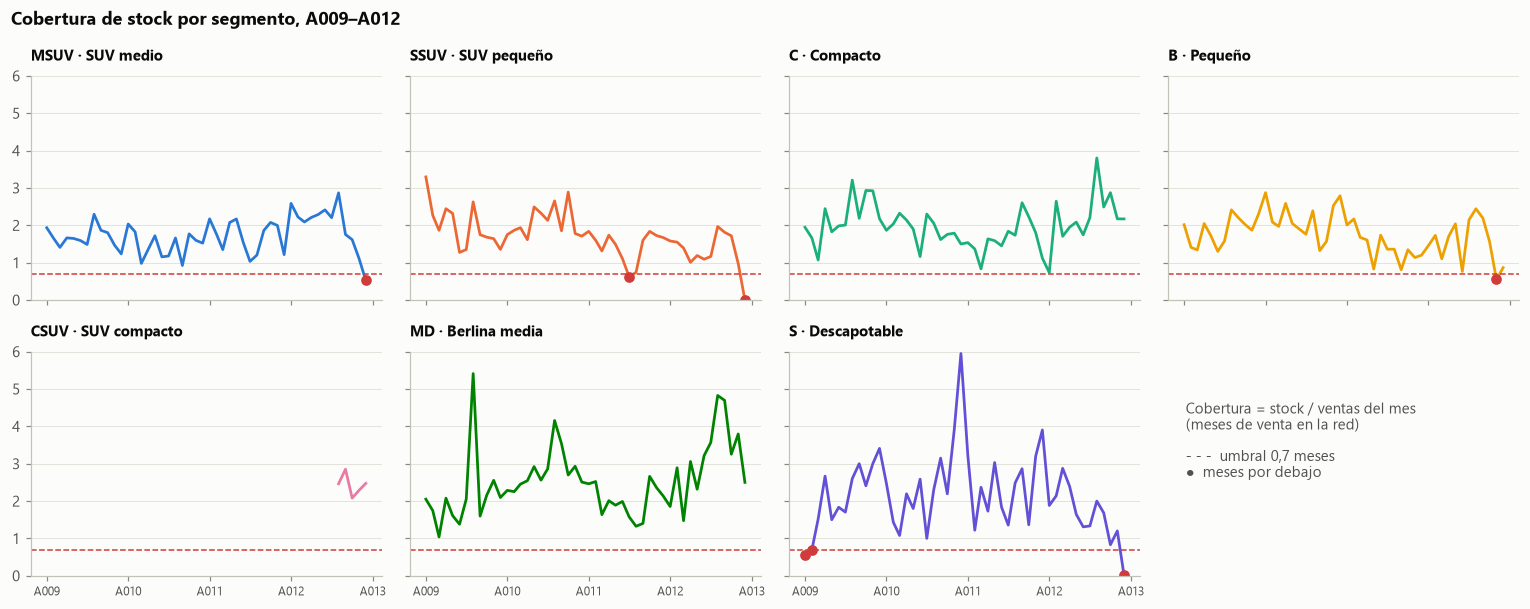

In [14]:
cob = (p["stock_total"] / p["ventas"]).unstack("segmento").loc["2009":]

fig, axes = plt.subplots(2, 4, figsize=(14, 5.6), sharex=True, sharey=True)
for ax, s in zip(axes.flat, SEGMENTOS):
    ax.plot(cob.index, cob[s], color=COLORES[s], lw=1.8)
    ax.axhline(0.7, color=ALERTA, lw=1, ls="--")
    bajos = cob.index[cob[s] < 0.7]
    ax.plot(bajos, cob.loc[bajos, s], "o", color=ALERTA, ms=6)
    ax.set_title(f"{s} · {NOMBRES[s]}", fontsize=10)
    eje_fechas(ax)
    ax.tick_params(axis="x", labelsize=8)
ax = axes.flat[-1]
ax.axis("off")
ax.text(0.05, 0.6, "Cobertura = stock / ventas del mes\n(meses de venta en la red)\n\n"
        "- - -  umbral 0,7 meses\n●  meses por debajo", fontsize=9.5, color=TINTA_2, va="center",
        transform=ax.transAxes)
axes[0, 0].set_ylim(0, 6)
fig.suptitle("Cobertura de stock por segmento, A009–A012", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "08_cobertura_segmentos")

In [15]:
bajos = (pl.assign(cobertura=pl.stock_total / pl.ventas)
         .query("anio >= 2009 and cobertura < 0.7")
         [["fecha", "segmento", "ventas", "stock_total", "cobertura"]])
bajos["fecha"] = bajos["fecha"].map(lambda f: f"{anio_caso(f.year)}-{f.month:02d}")
bajos.style.format({"ventas": es, "stock_total": es, "cobertura": lambda x: es(x, 2)}).hide(axis="index")

fecha,segmento,ventas,stock_total,cobertura
A009-01,S,57,32,"0,56"
A009-02,S,33,23,"0,70"
A011-07,SSUV,429,267,"0,62"
A012-11,B,204,112,"0,55"
A012-12,MSUV,1.023,536,"0,52"
A012-12,S,74,1,"0,01"
A012-12,SSUV,540,0,"0,00"


**Resultados.**
- Lo normal es tener **1,5–2,5 meses** de cobertura.
- En **diciembre de A012** tres segmentos se quedan casi sin coches: **SUV pequeño (0 coches)**, **descapotable (1 coche)** y **SUV medio (0,5 meses)**. El adelanto vació la red justo en los más vendidos.
- → Las ventas de nov–dic A012 en esos segmentos están **recortadas**: la demanda real (y el adelanto) fue algo mayor de lo que vemos.

Esto parece contradecir que "la red se llenó de coches". No lo hace: en verano de A012 la red estaba llena (el SUV medio llegó a casi 3 meses de cobertura, el compacto a casi 4 y la berlina a casi 5), y en diciembre el adelanto la vació **en unos segmentos sí y en otros no**. La distribución del stock a 31 de diciembre lo aclara:

In [16]:
dic = p.xs("2012-12-01", level="fecha").loc[SEGMENTOS, ["ventas", "stock_total", "s_91_180", "s_mas_180"]]
dic["cobertura (meses)"] = dic["stock_total"] / dic["ventas"]
dic["% del stock de la red"] = 100 * dic["stock_total"] / dic["stock_total"].sum()
dic.loc["TOTAL"] = dic.sum()
dic.loc["TOTAL", "cobertura (meses)"] = dic.loc["TOTAL", "stock_total"] / dic.loc["TOTAL", "ventas"]
dic.index = [f"{s} · {NOMBRES[s]}" if s in NOMBRES else s for s in dic.index]
dic.style.format({"ventas": es, "stock_total": es, "s_91_180": es, "s_mas_180": es,
                  "cobertura (meses)": lambda x: es(x, 1), "% del stock de la red": lambda x: es(x, 0)})

,ventas,stock_total,s_91_180,s_mas_180,cobertura (meses),% del stock de la red
MSUV · SUV medio,1.023,536,66,35,"0,5",19
SSUV · SUV pequeño,540,0,0,0,"0,0",0
C · Compacto,510,1.107,281,198,"2,2",38
B · Pequeño,112,97,0,0,"0,9",3
CSUV · SUV compacto,409,1.011,327,0,"2,5",35
MD · Berlina media,50,125,57,51,"2,5",4
S · Descapotable,74,1,0,1,"0,0",0
TOTAL,2.718,2.877,731,285,"1,1",100


**Resultados.** de los 2.877 coches de la red, **3 de cada 4 son compactos o SUV compactos**, mientras que el SUV pequeño y el descapotable están a cero.
- El SUV compacto es un lanzamiento: es normal "llenar la red" al principio para que haya coches de exposición.
- Pero el compacto tiene **2,2 meses** de stock y deja poco margen (1.187 €/coche).

> **El problema no es solo cuánto stock hay, sino dónde está.** Sobraban coches que dejan poco y faltaban los que más se venden. Esto refuerza que el plan se haga **segmento a segmento**.

**Limitación:** es stock a fin de mes. Un segmento puede quedarse sin coches a mitad de mes y reponer antes del cierre; eso no lo vemos.

## 6. Conclusiones: qué nos llevamos al modelo

### Respuesta a la pregunta 1
| | A011 | A012 | Variación |
|---|---|---|---|
| Ventas de Kaido | 21.362 | 23.175 | +8,5 % |
| Demanda limpia (sin automatriculaciones) | 19.543 | 20.706 | +6,0 % |
| Gama de siempre (sin SUV compacto) | 19.543 | 19.514 | −0,1 % |
| Gama de siempre sin el adelanto | 19.543 | ≈18.700 | **≈ −4 %** |

> *La demanda real de la gama de siempre **cae ≈4 %** en A012. El crecimiento de las ventas es un coche nuevo, automatriculaciones y ≈800 compras adelantadas que se restarán a A013.*

### Decisiones para el paso ② (modelo)
1. **Modelizar la demanda limpia** (`ventas − automat`), no las ventas.
2. Meter los **sucesos como variables 0/1** (`adelanto_compras`, `caida_tras_adelanto`, `incentivo_publico`, `subida_iva`).
3. **Diciembre A012 está censurado** en SSUV, S y MSUV: no fiarse de esos meses como demanda.
4. El **SUV compacto** solo tiene 5 meses de historia: necesita un tratamiento aparte (no se puede ajustar un modelo con 5 datos).
5. Las automatriculaciones siguen consumiendo stock: **decidir en la simulación** si se mantienen (≈11 %) o se reducen.
6. El stock de partida de A013 está **mal repartido** (sobran compactos y SUV compactos, faltan SUV pequeños y medios): el plan de los primeros meses será muy distinto por segmento.

### Gráficos candidatos para la presentación
Guardados en `salidas/figuras/`: la **descomposición del crecimiento** (02) y el **mercado con sus sucesos** (06) cuentan la historia de A012 en dos imágenes.